# FCAL v2.1 — Per-Layer Loss + Adaptive Lambda + Bug fixes
### Fixes the ViT gradient dilution problem from v1, and the ResNet-v2 issues from v2.0

| | v1 | v2 (this notebook, v2.1) |
|---|---|---|
| ViT attention signal | Rollout across all 12 layers | Per-layer: FCAL applied at last N layers directly |
| Lambda | Fixed cosine schedule | Adaptive (GradNorm-style): lambda = alpha * CE / FCAL |
| Baselines | Retrained from scratch | Loaded from saved checkpoints |

**v2.1 fixes over v2.0:**
- ResNet CAM passed to FCAL is now the *raw* ReLU(CAM); min-max stays as a
  visualization helper only. (v2.0 fed a min-max-stretched CAM into the loss,
  destroying magnitude information and routing gradients through per-image
  min/max statistics.)
- ResNet adaptive lambda now uses the same CE/FCAL direction as the ViT branch;
  v2.0 used FCAL/CE which saturates to lam_max almost immediately and stops adapting.
- ResNet warmup reduced 10 -> 5 epochs (matches ViT).
- `force_retrain_resnet_v2` now defaults to False (the previous default silently
  deleted any existing checkpoint).
- Added optional *intra-foreground entropy* bonus that rewards concentrated
  attention inside the mask — directly enforces the paper's 'free *and* focused'
  claim instead of relying on the architecture alone to concentrate.
- Added optional *focal containment* variant that weights background pixels by
  their current attention mass, pushing the worst-leaking pixels hardest.


## 0 — Install

In [1]:
!pip install timm torchmetrics matplotlib seaborn tqdm kagglehub -q

import torch
print(f'PyTorch {torch.__version__}  |  CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}  |  VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f}GB')


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch 2.13.0.dev20260421+cu130  |  CUDA: True
GPU: NVIDIA GeForce RTX 5070 Ti  |  VRAM: 17.1GB


## 1 — Imports & Config

In [2]:
import os, math, json, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
import torchvision.models as models
from torchvision import transforms
from PIL import Image
import timm
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')
torch.backends.cudnn.benchmark = True
torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

CFG = dict(
    img_size       = 224,
    batch_size     = 32,
    num_workers    = 4,
    num_epochs     = 50,
    lr_vit         = 5e-5,
    lr_resnet      = 2e-4,
    weight_decay   = 1e-4,
    warmup_epochs  = 5,
    # --- v2 specific (ViT defaults) ---
    lambda_max     = 1.0,
    lambda_min     = 0.05,
    adapt_alpha    = 0.5,
    per_layer_last_n = 6,
    dilation_px    = 3,
    # --- ResNet-v2 safer adaptive settings ---
    warmup_epochs_resnet_v2 = 5,        # v2.1: was 10 — too long on 50-ep schedule
    lambda_max_resnet_v2    = 0.30,
    lambda_min_resnet_v2    = 0.02,
    adapt_alpha_resnet_v2   = 0.15,
    force_retrain_resnet_v2 = False,    # v2.1: flip to True manually if you really want to wipe the ckpt
    # --- v2.1 additions (entropy bonus + focal containment) ---
    entropy_bonus_weight    = 0.05,     # weight on -H(P|foreground); 0 disables
    use_focal_containment   = False,    # if True, weight bg penalty by current attention
    # --- checkpoint paths from v1 (edit these to match your saved filenames) ---
    ckpt_vit_base  = 'ckpt_CUB_ViT_Baseline.pth',
    ckpt_vit_v1    = 'ckpt_CUB_ViT_FCAL.pth',
)
print(json.dumps(CFG, indent=2))

Using device: cuda
{
  "img_size": 224,
  "batch_size": 32,
  "num_workers": 4,
  "num_epochs": 50,
  "lr_vit": 5e-05,
  "lr_resnet": 0.0002,
  "weight_decay": 0.0001,
  "warmup_epochs": 5,
  "lambda_max": 1.0,
  "lambda_min": 0.05,
  "adapt_alpha": 0.5,
  "per_layer_last_n": 6,
  "dilation_px": 3,
  "warmup_epochs_resnet_v2": 5,
  "lambda_max_resnet_v2": 0.3,
  "lambda_min_resnet_v2": 0.02,
  "adapt_alpha_resnet_v2": 0.15,
  "force_retrain_resnet_v2": false,
  "entropy_bonus_weight": 0.05,
  "use_focal_containment": false,
  "ckpt_vit_base": "ckpt_CUB_ViT_Baseline.pth",
  "ckpt_vit_v1": "ckpt_CUB_ViT_FCAL.pth"
}


## 2 — FCAL Losses (v1 original + v2 per-layer)

We keep v1 intact for comparison. v2 adds two things:
1. `fcal_loss_perlayer` — applies containment loss directly to each layer's attention map
2. `get_adaptive_lambda` — scales lambda based on the live CE/FCAL ratio

In [3]:
# ─────────────────────────────────────────────────────────────────
# Shared utility
# ─────────────────────────────────────────────────────────────────

def dilate_mask(mask, px=3):
    """Dilate foreground mask by px pixels to create soft boundary tolerance."""
    if px == 0:
        return mask
    k = 2 * px + 1
    kernel  = torch.ones(1, 1, k, k, device=mask.device)
    dilated = F.conv2d(mask.float(), kernel, padding=px).clamp(0, 1)
    return dilated  # (B, 1, H, W)


def normalize_cam(cam):
    """
    Normalize a CAM (B, H, W) into a probability distribution.
    Each image's map sums to 1. Gradient w.r.t. foreground pixels = 0.
    """
    B = cam.shape[0]
    cam_relu = F.relu(cam)
    flat     = cam_relu.view(B, -1)
    prob     = flat / (flat.sum(dim=1, keepdim=True) + 1e-8)
    return prob.view_as(cam)


def containment_penalty(cam_prob, mask, dilation_px=3):
    """
    Core FCAL computation given an already-normalized cam_prob (B, Hc, Wc)
    and a binary mask (B, 1, Hm, Wm).

    Returns scalar in [0, 1] = mean fraction of attention on background.
    Gradient is exactly zero for foreground pixels by construction.
    """
    B, Hc, Wc = cam_prob.shape
    _, _, Hm, Wm = mask.shape

    # Downsample mask to CAM resolution
    mask_small = F.interpolate(
        mask.float(), size=(Hc, Wc),
        mode='bilinear', align_corners=False
    )  # (B, 1, Hc, Wc)

    # Dilate at CAM resolution
    scale = max(1, Hm // Hc)
    mask_dilated = dilate_mask(mask_small, px=max(1, dilation_px // scale))
    mask_dilated = mask_dilated.squeeze(1).clamp(0, 1)  # (B, Hc, Wc)

    background = 1.0 - mask_dilated  # 1=background, 0=foreground

    leakage = (cam_prob * background).sum(dim=(1, 2))  # (B,)
    return leakage.mean()


# ─────────────────────────────────────────────────────────────────
# v1 loss (rollout-based, kept for comparison)
# ─────────────────────────────────────────────────────────────────

def fcal_loss_v1(cam, mask, dilation_px=3):
    """Original v1 FCAL — applied once to the rollout map."""
    cam_prob = normalize_cam(cam)
    return containment_penalty(cam_prob, mask, dilation_px)


# ─────────────────────────────────────────────────────────────────
# v2 loss (per-layer — the fix for ViT gradient dilution)
# ─────────────────────────────────────────────────────────────────

def fcal_loss_perlayer(layer_cams, mask, dilation_px=3, layer_weights=None):
    """
    Per-layer FCAL for ViT.

    Instead of computing rollout and applying FCAL once at the end,
    we apply FCAL independently to each layer's CLS attention map.

    Why this fixes the gradient dilution problem:
    - Rollout = product of 12 matrices. Gradient must pass through all 12 in reverse.
      Signal dilutes. By layer 1, the gradient is near zero.
    - Per-layer: FCAL_l is applied directly to layer l's attention weights.
      Gradient for FCAL_12 travels through 1 layer. For FCAL_6, through 6 layers.
      Every layer gets a direct, undiluted signal.

    Args:
        layer_cams     : list of (B, G, G) tensors, one per layer
                         where G = patch grid size (14 for ViT-Base)
        mask           : (B, 1, H, W) binary GT mask
        dilation_px    : soft boundary tolerance
        layer_weights  : optional list of floats, one per layer.
                         If None, uses linear ramp (later layers weighted higher)
                         because later layers have more spatial semantic content.

    Returns:
        scalar: weighted mean containment loss across all layers
    """
    n = len(layer_cams)

    if layer_weights is None:
        # Linear ramp: layer 0 gets weight 1/(n), layer n-1 gets weight n/n
        # Later layers have cleaner spatial attention, so they get more weight.
        raw     = torch.arange(1, n + 1, dtype=torch.float32)
        weights = (raw / raw.sum()).tolist()
    else:
        total   = sum(layer_weights)
        weights = [w / total for w in layer_weights]

    total_loss = 0.0
    for cam, w in zip(layer_cams, weights):
        cam_prob    = normalize_cam(cam)
        layer_loss  = containment_penalty(cam_prob, mask, dilation_px)
        total_loss  = total_loss + w * layer_loss

    return total_loss


# ─────────────────────────────────────────────────────────────────
# Lambda schedules — fixed (v1) and adaptive (v2)
# ─────────────────────────────────────────────────────────────────

def get_lambda_fixed(epoch, total_epochs, warmup, lam_max, lam_min):
    """v1: fixed cosine schedule, blind to training dynamics."""
    if epoch < warmup:
        return 0.0
    t = (epoch - warmup) / max(total_epochs - warmup, 1)
    return lam_min + (lam_max - lam_min) * 0.5 * (1 + math.cos(math.pi * t))


def get_lambda_adaptive(epoch, warmup, ce_value, fcal_value, alpha=0.5,
                        lam_max=1.0, lam_min=0.01):
    """
    v2 adaptive lambda — GradNorm-style loss balancing.

    Goal: keep lambda*FCAL proportional to alpha*CE throughout training,
    so the spatial term contributes a stable fraction of the total loss
    regardless of where the model is in its trajectory.

    Setting lambda*FCAL = alpha*CE gives lambda = alpha*CE/FCAL.
        Early: CE is large, FCAL moderate -> lambda is large
               (so the FCAL term is kept in scale with CE).
        Late : CE shrinks, FCAL plateau   -> lambda shrinks
               (so CE is allowed to refine without being overwhelmed).

    Formula:
        lambda = clip( alpha * (ce / fcal), lam_min, lam_max )

    The ratio is self-normalizing — works regardless of absolute loss magnitudes
    and regardless of architecture / num_classes.

    Args:
        epoch     : current epoch (0-indexed)
        warmup    : number of warmup epochs (lambda=0 during warmup)
        ce_value  : current batch CE loss value (detached float)
        fcal_value: current batch FCAL loss value (detached float)
        alpha     : overall scaling factor
        lam_max   : hard ceiling
        lam_min   : hard floor (after warmup)

    Returns:
        float: lambda for this step
    """
    if epoch < warmup:
        return 0.0
    if fcal_value < 1e-8:
        return lam_min
    raw = alpha * (ce_value / (fcal_value + 1e-8))
    return float(np.clip(raw, lam_min, lam_max))



# -----------------------------------------------------------------
# v2.1 additions: intra-foreground entropy bonus + focal containment
# -----------------------------------------------------------------

def intra_fg_entropy(cam_prob, mask, dilation_px=3, eps=1e-8):
    """
    Entropy of the attention distribution RESTRICTED to foreground pixels.
    Minimizing this entropy rewards concentrated focus inside the object —
    directly operationalizing the paper's 'free but focused' claim.
    Returns scalar mean entropy in nats.
    """
    B, Hc, Wc = cam_prob.shape
    _, _, Hm, Wm = mask.shape
    m = F.interpolate(mask.float(), size=(Hc, Wc), mode='bilinear', align_corners=False)
    scale = max(1, Hm // Hc)
    m = dilate_mask(m, px=max(1, dilation_px // scale)).squeeze(1).clamp(0, 1)
    fg_mass = (cam_prob * m).sum(dim=(1, 2)) + eps                # (B,)
    p_fg = (cam_prob * m) / fg_mass.view(-1, 1, 1)                # renormalize on FG
    ent = -(p_fg * (p_fg + eps).log()).sum(dim=(1, 2))            # (B,)
    return ent.mean()


def fcal_loss_focal(cam, mask, dilation_px=3, gamma=2.0):
    """
    Focal-containment variant: weight each background pixel's contribution by
    its own current attention mass (detached) raised to gamma. The few
    highly-attended background pixels get pushed disproportionately harder,
    while near-zero background pixels are essentially ignored.
    """
    cam_prob = normalize_cam(cam)
    B, Hc, Wc = cam_prob.shape
    _, _, Hm, Wm = mask.shape
    m = F.interpolate(mask.float(), size=(Hc, Wc), mode='bilinear', align_corners=False)
    scale = max(1, Hm // Hc)
    m = dilate_mask(m, px=max(1, dilation_px // scale)).squeeze(1).clamp(0, 1)
    bg = 1.0 - m
    weight = (cam_prob.detach() * bg).pow(gamma)
    leakage = (cam_prob * bg * (1.0 + weight)).sum(dim=(1, 2))
    return leakage.mean()


# ─────────────────────────────────────────────────────────────────
# Sanity checks
# ─────────────────────────────────────────────────────────────────
perfect_cam  = torch.zeros(2, 7, 7); perfect_cam[:, 2:5, 2:5] = 1.0
perfect_mask = torch.zeros(2, 1, 224, 224); perfect_mask[:, :, 50:180, 50:180] = 1.0
bad_cam      = torch.zeros(2, 7, 7); bad_cam[:, 0, 0] = 1.0
small_mask   = torch.zeros(2, 1, 224, 224); small_mask[:, :, 180:224, 180:224] = 1.0

print(f'v1 perfect (expect ~0): {fcal_loss_v1(perfect_cam, perfect_mask):.6f}')
print(f'v1 bad     (expect ~1): {fcal_loss_v1(bad_cam,     small_mask):.6f}')

# Per-layer test: simulate 6 layers each with same cam
layer_cams = [perfect_cam.clone() for _ in range(6)]
print(f'v2 per-layer perfect:   {fcal_loss_perlayer(layer_cams, perfect_mask):.6f}')
layer_cams_bad = [bad_cam.clone() for _ in range(6)]
print(f'v2 per-layer bad:       {fcal_loss_perlayer(layer_cams_bad, small_mask):.6f}')

# Adaptive lambda behaviour
print(f'\nAdaptive lambda examples:')
print(f'  Early (ce=2.5, fcal=0.51):  λ = {get_lambda_adaptive(5,5,2.5,0.51,0.5,1.0,0.01):.4f}')  # just after warmup
print(f'  Mid   (ce=0.1, fcal=0.45):  λ = {get_lambda_adaptive(25,5,0.1,0.45,0.5,1.0,0.01):.4f}')
print(f'  Late  (ce=0.01,fcal=0.38):  λ = {get_lambda_adaptive(45,5,0.01,0.38,0.5,1.0,0.01):.4f}')

v1 perfect (expect ~0): 0.000000
v1 bad     (expect ~1): 1.000000
v2 per-layer perfect:   0.000000
v2 per-layer bad:       1.000000

Adaptive lambda examples:
  Early (ce=2.5, fcal=0.51):  λ = 1.0000
  Mid   (ce=0.1, fcal=0.45):  λ = 0.1111
  Late  (ce=0.01,fcal=0.38):  λ = 0.0132


## 3 — Dataset Setup (same as v1)

In [4]:
def find_root(base, marker_files):
    """Recursively search for a directory containing all marker files."""
    base = Path(base)
    for root, dirs, files in os.walk(base):
        if all(m in files for m in marker_files):
            return Path(root)
    raise FileNotFoundError(f'Cannot find dataset root under {base}')

# Try local path first, then Kaggle
local_candidates = [
    Path('d:/AI Research/cub2002011'),  # Will search versions/7/CUB_200_2011 recursively
    Path.cwd() / 'cub2002011',
    Path.cwd().parent / 'cub2002011',
]

CUB_ROOT = None
for candidate in local_candidates:
    if candidate.exists():
        try:
            CUB_ROOT = find_root(candidate, ['images.txt', 'train_test_split.txt'])
            print(f'✓ Found local CUB dataset at: {CUB_ROOT}')
            break
        except FileNotFoundError:
            pass

if CUB_ROOT is None:
    print("Local CUB not found. Please ensure CUB dataset is in: d:\\AI Research\\cub2002011")
    raise FileNotFoundError("CUB dataset not found at expected location")

# Segmentations are typically in the same parent directory as CUB_200_2011
# Or in the versions/7 parent
seg_candidates = [
    CUB_ROOT.parent / 'segmentations',
    Path('d:/AI Research/cub2002011/versions/7/segmentations'),
    CUB_ROOT / 'segmentations',
]
CUB_SEG_ROOT = next((p for p in seg_candidates if p.exists()), None)

if CUB_SEG_ROOT is None:
    print(f"⚠ Warning: Cannot find CUB segmentations.")
    print("Checked:")
    for p in seg_candidates:
        exists_str = "✓" if p.exists() else "✗"
        print(f"  {exists_str} {p}")
    print("Continuing without masks - model will train on images only.\n")
else:
    print(f'✓ Found segmentations at: {CUB_SEG_ROOT}\n')

print(f'Dataset configuration:')
print(f'  CUB_ROOT = {CUB_ROOT}')
print(f'  CUB_SEG_ROOT = {CUB_SEG_ROOT}')

images = pd.read_csv(CUB_ROOT/'images.txt',             sep=' ', header=None, names=['id','path'])
labels = pd.read_csv(CUB_ROOT/'image_class_labels.txt', sep=' ', header=None, names=['id','label'])
splits = pd.read_csv(CUB_ROOT/'train_test_split.txt',   sep=' ', header=None, names=['id','is_train'])
cub_df = images.merge(labels, on='id').merge(splits, on='id')
cub_df['label']     = cub_df['label'] - 1
cub_df['img_path']  = cub_df['path'].apply(lambda x: str(CUB_ROOT/'images'/x))
if CUB_SEG_ROOT is not None:
    cub_df['mask_path'] = cub_df['path'].apply(lambda x: str(CUB_SEG_ROOT/x.replace('.jpg', '.png')))
    cub_df['has_mask']  = cub_df['mask_path'].apply(os.path.exists)
else:
    cub_df['mask_path'] = None
    cub_df['has_mask']  = False

cub_train = cub_df[cub_df['is_train']==1].reset_index(drop=True)
cub_test  = cub_df[cub_df['is_train']==0].reset_index(drop=True)
print(f'\nCUB dataset summary:')
print(f'  Train images: {len(cub_train):,}')
print(f'  Test images:  {len(cub_test):,}')
print(f'  Masks found:  {cub_df.has_mask.sum():,} / {len(cub_df):,}')

cub_classes = {}
with open(CUB_ROOT/'classes.txt') as f:
    for line in f:
        i, name = line.strip().split(' ', 1)
        cub_classes[int(i)-1] = name.split('.')[-1].replace('_',' ')

✓ Found local CUB dataset at: d:\AI Research\cub2002011\versions\7\CUB_200_2011
✓ Found segmentations at: d:\AI Research\cub2002011\versions\7\segmentations

Dataset configuration:
  CUB_ROOT = d:\AI Research\cub2002011\versions\7\CUB_200_2011
  CUB_SEG_ROOT = d:\AI Research\cub2002011\versions\7\segmentations

CUB dataset summary:
  Train images: 5,994
  Test images:  5,794
  Masks found:  11,788 / 11,788


In [5]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]
S    = CFG['img_size']

train_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.RandomGrayscale(p=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
mask_tf = transforms.Compose([
    transforms.Resize((S, S), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor(),
])


class FGVCDataset(Dataset):
    def __init__(self, df, img_tf, mask_tf, hflip_prob=0.0):
        self.df = df; self.img_tf = img_tf; self.mask_tf = mask_tf
        self.hflip_prob = hflip_prob

    def __len__(self): return len(self.df)

    def __getitem__(self, i):
        row   = self.df.iloc[i]
        img   = Image.open(row.img_path).convert('RGB')
        label = int(row.label)
        if row.has_mask and os.path.exists(row.mask_path):
            mask = Image.open(row.mask_path).convert('L')
        else:
            mask = Image.new('L', img.size, 255)
        if self.hflip_prob > 0 and torch.rand(1).item() < self.hflip_prob:
            img  = transforms.functional.hflip(img)
            mask = transforms.functional.hflip(mask)
        img  = self.img_tf(img)
        mask = self.mask_tf(mask)
        mask = (mask > 0.5).float()
        return img, label, mask


def denorm(t):
    m = torch.tensor(MEAN)[:,None,None]
    s = torch.tensor(STD)[:,None,None]
    return (t * s + m).clamp(0, 1)


effective_workers = 0 if os.name == 'nt' else CFG['num_workers']

cub_train_ds = FGVCDataset(cub_train, train_tf, mask_tf, hflip_prob=0.5)
cub_test_ds  = FGVCDataset(cub_test,  val_tf,   mask_tf, hflip_prob=0.0)
cub_train_loader = DataLoader(cub_train_ds, CFG['batch_size'], shuffle=True,
                              num_workers=effective_workers, pin_memory=True, drop_last=True)
cub_test_loader  = DataLoader(cub_test_ds,  CFG['batch_size'], shuffle=False,
                              num_workers=effective_workers, pin_memory=True)
print(f'CUB loaders ready — Train batches: {len(cub_train_loader)}')

CUB loaders ready — Train batches: 187


## 4 — ViT-Base v2 Model (with per-layer attention capture)

Key difference from v1: `get_layer_cams()` returns a list of per-layer attention maps
that still have their gradients attached — this is what allows per-layer backpropagation.

In v1, `attn.detach()` was called inside the hook, killing gradients before they could be used.

In [6]:
class ViTBaseV2(nn.Module):
    """
    ViT-Base with per-layer attention capture.

    Critical difference from v1:
    - v1 stored attn.detach() inside the hook -> no gradient through attention
    - v2 stores raw attn (with grad) -> per-layer FCAL can backprop directly

    get_layer_cams(last_n) returns the CLS->patch attention maps for the
    last `last_n` layers. These are (B, G, G) tensors with gradients intact.
    """
    def __init__(self, num_classes=200, pretrained=True):
        super().__init__()
        self.vit = timm.create_model(
            'vit_base_patch16_224', pretrained=pretrained, num_classes=num_classes
        )
        self._layer_attns = []  # populated during forward
        self._register_hooks()

    def _register_hooks(self):
        """Register hooks on every block to capture head-averaged attention WITH gradients."""
        for block in self.vit.blocks:
            store = self._layer_attns

            def make_fwd(attn_mod, store):
                def fwd(x, attn_mask=None, is_causal=False):
                    B, N, C = x.shape
                    qkv = attn_mod.qkv(x).reshape(
                        B, N, 3, attn_mod.num_heads, C // attn_mod.num_heads
                    ).permute(2, 0, 3, 1, 4)
                    q, k, v = qkv.unbind(0)
                    attn = (q @ k.transpose(-2, -1)) * attn_mod.scale
                    attn = attn.softmax(dim=-1)
                    # NOTE: NO .detach() here -- gradients preserved
                    store.append(attn)  
                    x = (attn @ v).transpose(1, 2).reshape(B, N, C)
                    x = attn_mod.proj(x)
                    x = attn_mod.proj_drop(x)
                    return x
                return fwd

            block.attn.forward = make_fwd(block.attn, self._layer_attns)

    def forward(self, x):
        self._layer_attns.clear()
        return self.vit(x)

    def get_layer_cams(self, last_n=6):
        """
        Extract CLS->patch attention maps from the last N layers.
        Returns list of (B, G, G) tensors WITH gradients.

        Why last N instead of all 12:
        - Early layers attend very locally / randomly in semantic terms
        - Applying FCAL to them adds noise to the gradient
        - Later layers have meaningful spatial attention worth supervising
        """
        selected = self._layer_attns[-last_n:]  # last N layers
        cams = []
        for attn in selected:
            # attn: (B, num_heads, N, N)  N = 1 + num_patches
            avg     = attn.mean(dim=1)          # (B, N, N) -- head average
            cls_att = avg[:, 0, 1:]             # (B, num_patches) -- CLS row, skip CLS col
            G       = int(cls_att.shape[-1] ** 0.5)
            cam     = cls_att.reshape(-1, G, G) # (B, G, G)
            cams.append(cam)
        return cams

    def get_rollout_cam(self):
        """v1-style rollout (for comparison / evaluation metric). Uses detached attns."""
        rollout = None
        for attn in self._layer_attns:
            avg  = attn.detach().mean(1)
            eye  = torch.eye(avg.shape[-1], device=avg.device).unsqueeze(0)
            avg  = (avg + eye) / 2
            avg  = avg / avg.sum(-1, keepdim=True)
            rollout = avg if rollout is None else torch.bmm(avg, rollout)
        cls = rollout[:, 0, 1:]
        G   = int(cls.shape[-1] ** 0.5)
        amap = cls.reshape(-1, G, G)
        fl   = amap.view(amap.shape[0], -1)
        mn   = fl.min(1).values.view(-1,1,1)
        mx   = fl.max(1).values.view(-1,1,1)
        return (amap - mn) / (mx - mn + 1e-8)


# Quick test
m = ViTBaseV2(num_classes=200).to(DEVICE)
x = torch.randn(2, 3, 224, 224).to(DEVICE)
out = m(x)
layer_cams = m.get_layer_cams(last_n=CFG['per_layer_last_n'])
print(f'ViT logits: {out.shape}')
print(f'Per-layer cams: {len(layer_cams)} layers, each shape: {layer_cams[0].shape}')
print(f'Gradients attached: {layer_cams[0].requires_grad}')

ViT logits: torch.Size([2, 200])
Per-layer cams: 6 layers, each shape: torch.Size([2, 14, 14])
Gradients attached: True


## 5 — Load Pretrained Baselines from v1

We already have the baseline checkpoints. No need to retrain.
We just load them and measure their leakage as the reference point.

In [7]:
@torch.no_grad()
def compute_leakage(model, loader, device, n_batches=30, use_rollout=True):
    """
    Compute mean attention leakage over n_batches.
    Always uses rollout for ViT (fair comparison across v1 and v2).
    """
    model.eval()
    leaks = []
    for i, (imgs, labels, masks) in enumerate(loader):
        if i >= n_batches: break
        imgs, labels, masks = imgs.to(device), labels.to(device), masks.to(device)
        _ = model(imgs)
        if hasattr(model, 'get_rollout_cam'):
            cam = model.get_rollout_cam()
        else:
            cam = model.get_cam(class_idx=labels)
        leak = fcal_loss_v1(cam, masks, dilation_px=0)  # no dilation for metric
        leaks.append(leak.item())
    return float(np.mean(leaks))


# Load v1 ViT baseline checkpoint
# Adjust the checkpoint filename below to match what v1 saved
CKPT_BASE = CFG['ckpt_vit_base']  # e.g. 'ckpt_CUB_ViT_Baseline.pth'

vit_baseline = ViTBaseV2(num_classes=200, pretrained=False).to(DEVICE)

if os.path.exists(CKPT_BASE):
    vit_baseline.load_state_dict(torch.load(CKPT_BASE, map_location=DEVICE))
    baseline_leak = compute_leakage(vit_baseline, cub_test_loader, DEVICE, n_batches=50)
    print(f'Loaded baseline checkpoint: {CKPT_BASE}')
    print(f'Baseline leakage (rollout): {baseline_leak:.4f}')
else:
    print(f'WARNING: checkpoint not found at {CKPT_BASE}')
    print('Set CFG["ckpt_vit_base"] to the correct path from your v1 run.')
    print('Baseline leakage from logs: ~0.49')
    baseline_leak = 0.49  # from v1 logs

Set CFG["ckpt_vit_base"] to the correct path from your v1 run.
Baseline leakage from logs: ~0.49


## 6 — Training Loop v2

Key changes from v1:
1. Uses `get_layer_cams()` instead of `get_cam()` (rollout)
2. Uses `fcal_loss_perlayer()` instead of `fcal_loss_v1()`
3. Uses `get_lambda_adaptive()` which updates every batch, not every epoch
4. Logs `lambda_ema` — the exponential moving average of lambda so you can see how it evolves

In [8]:
def train_epoch_v2(model, loader, optimizer, epoch, total_epochs, device):
    """
    Training epoch with per-layer FCAL and adaptive lambda.
    """
    model.train()
    ce_fn = nn.CrossEntropyLoss()

    stats = dict(loss=0, ce=0, fcal=0, correct=0, total=0, lam_sum=0)
    n_batches = len(loader)

    for imgs, labels, masks in tqdm(loader, desc=f'  ep{epoch:02d}', leave=False):
        imgs, labels, masks = imgs.to(device), labels.to(device), masks.to(device)
        labels = labels.long()
        optimizer.zero_grad(set_to_none=True)

        logits    = model(imgs)
        loss_ce   = ce_fn(logits, labels)

        if epoch < CFG['warmup_epochs']:
            # Warmup: no FCAL, pure CE
            loss        = loss_ce
            loss_fcal_v = 0.0
            lam         = 0.0
        else:
            # Per-layer FCAL
            layer_cams  = model.get_layer_cams(last_n=CFG['per_layer_last_n'])
            loss_fcal   = fcal_loss_perlayer(layer_cams, masks, CFG['dilation_px'])
            loss_fcal_v = loss_fcal.item()

            # Adaptive lambda: computed from current batch CE and FCAL values
            lam = get_lambda_adaptive(
                epoch, CFG['warmup_epochs'],
                ce_value   = loss_ce.item(),
                fcal_value = loss_fcal_v,
                alpha      = CFG['adapt_alpha'],
                lam_max    = CFG['lambda_max'],
                lam_min    = CFG['lambda_min'],
            )
            loss = loss_ce + lam * loss_fcal

            # v2.1: optional intra-foreground entropy bonus, applied to the
            # last layer's attention map (closest to the CLS prediction).
            ent_w = CFG.get('entropy_bonus_weight', 0.0)
            if ent_w > 0:
                last_cam_prob = normalize_cam(layer_cams[-1])
                ent = intra_fg_entropy(last_cam_prob, masks, dilation_px=CFG['dilation_px'])
                loss = loss + lam * ent_w * ent

        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite loss. Check CE and FCAL values.')

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        stats['loss']    += loss.item()
        stats['ce']      += loss_ce.item()
        stats['fcal']    += loss_fcal_v
        stats['lam_sum'] += lam
        stats['correct'] += (logits.argmax(1) == labels).sum().item()
        stats['total']   += labels.size(0)

    n = n_batches
    return {
        'acc'    : stats['correct'] / stats['total'],
        'loss'   : stats['loss']    / n,
        'ce'     : stats['ce']      / n,
        'fcal'   : stats['fcal']    / n,
        'lambda' : stats['lam_sum'] / n,  # mean lambda across batches this epoch
    }


@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    ce_fn = nn.CrossEntropyLoss()
    total_loss = correct = total = 0
    for imgs, labels, _ in tqdm(loader, desc='  eval', leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        logits = model(imgs)
        total_loss += ce_fn(logits, labels).item()
        correct    += (logits.argmax(1) == labels).sum().item()
        total      += labels.size(0)
    return {'loss': total_loss / len(loader), 'acc': correct / total}

## 7 — Run FCAL v2 Experiment

In [9]:
def run_v2(name, num_classes, train_loader, test_loader, epochs=None):
    epochs = epochs or CFG['num_epochs']
    print(f'\n{"="*65}')
    print(f'  {name}  (per-layer FCAL + adaptive lambda)  ep={epochs}')
    print(f'{"="*65}')

    model     = ViTBaseV2(num_classes=num_classes).to(DEVICE)
    optimizer = optim.AdamW(model.parameters(), lr=CFG['lr_vit'],
                            weight_decay=CFG['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=CFG['lr_vit'] * 0.01)

    hist = {k: [] for k in ['train_acc','val_acc','ce','fcal','lambda','leak']}
    best_acc, best_path = 0.0, f'ckpt_{name.replace(" ","_")}_v2.pth'

    for ep in range(1, epochs + 1):
        tr = train_epoch_v2(model, train_loader, optimizer, ep, epochs, DEVICE)
        va = evaluate(model, test_loader, DEVICE)
        scheduler.step()

        # Measure leakage every 5 epochs using rollout (same metric as v1 for fair comparison)
        leak = compute_leakage(model, test_loader, DEVICE) if ep % 5 == 0 else float('nan')

        for k, v in [('train_acc', tr['acc']), ('val_acc', va['acc']),
                     ('ce', tr['ce']), ('fcal', tr['fcal']),
                     ('lambda', tr['lambda']), ('leak', leak)]:
            hist[k].append(v)

        if va['acc'] > best_acc:
            best_acc = va['acc']
            torch.save(model.state_dict(), best_path)

        leak_s = f'{leak:.4f}' if not math.isnan(leak) else '----'
        print(f'  ep{ep:02d}/{epochs}  '
              f'tr={tr["acc"]:.4f}  va={va["acc"]:.4f}  '
              f'ce={tr["ce"]:.3f}  fcal={tr["fcal"]:.4f}  '
              f'lam={tr["lambda"]:.3f}  leak={leak_s}  best={best_acc:.4f}')

    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    return model, hist, best_acc


# Run it
vit_v2, hist_v2, acc_v2 = run_v2(
    'CUB ViT FCAL v2', num_classes=200,
    train_loader=cub_train_loader,
    test_loader=cub_test_loader,
)


  CUB ViT FCAL v2  (per-layer FCAL + adaptive lambda)  ep=50


  ep01:   0%|          | 0/187 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 8 — Compare v1 vs v2 vs Baseline

In [ ]:
# Load v1 FCAL checkpoint for comparison if available
CKPT_V1 = CFG['ckpt_vit_v1']

vit_v1 = ViTBaseV2(num_classes=200, pretrained=False).to(DEVICE)
if os.path.exists(CKPT_V1):
    vit_v1.load_state_dict(torch.load(CKPT_V1, map_location=DEVICE))
    v1_leak = compute_leakage(vit_v1, cub_test_loader, DEVICE, n_batches=50)
    v1_acc  = evaluate(vit_v1, cub_test_loader, DEVICE)['acc']
    print(f'v1 FCAL loaded: acc={v1_acc:.4f}  leak={v1_leak:.4f}')
else:
    print('v1 checkpoint not found, using values from logs')
    v1_leak = 0.4925   # ep50 from your logs
    v1_acc  = 0.8114

# Final v2 metrics
v2_leak = compute_leakage(vit_v2, cub_test_loader, DEVICE, n_batches=50)
v2_acc  = acc_v2

print(f'\n{"="*55}')
print(f'  CUB-200-2011 ViT-Base — Final Comparison')
print(f'{"="*55}')
print(f'  {"Method":<30} {"Top-1":>8}  {"Leakage":>8}')
print(f'  {"-"*50}')
print(f'  {"Baseline (CE only)":<30} {baseline_leak:>8.4f}  (acc from logs: 0.8114)')
print(f'  {"FCAL v1 (rollout, fixed λ=0.3)":<30} {v1_leak:>8.4f}  {v1_acc:>8.4f}')
print(f'  {"FCAL v2 (per-layer, adaptive λ)":<30} {v2_leak:>8.4f}  {v2_acc:>8.4f}')
print(f'{"="*55}')

v1 checkpoint not found, using values from logs

  CUB-200-2011 ViT-Base — Final Comparison
  Method                            Top-1   Leakage
  --------------------------------------------------
  Baseline (CE only)               0.4900  (acc from logs: 0.8114)
  FCAL v1 (rollout, fixed λ=0.3)   0.4925    0.8114
  FCAL v2 (per-layer, adaptive λ)   0.4102    0.7901


## 9 — Training Curves: v1 vs v2

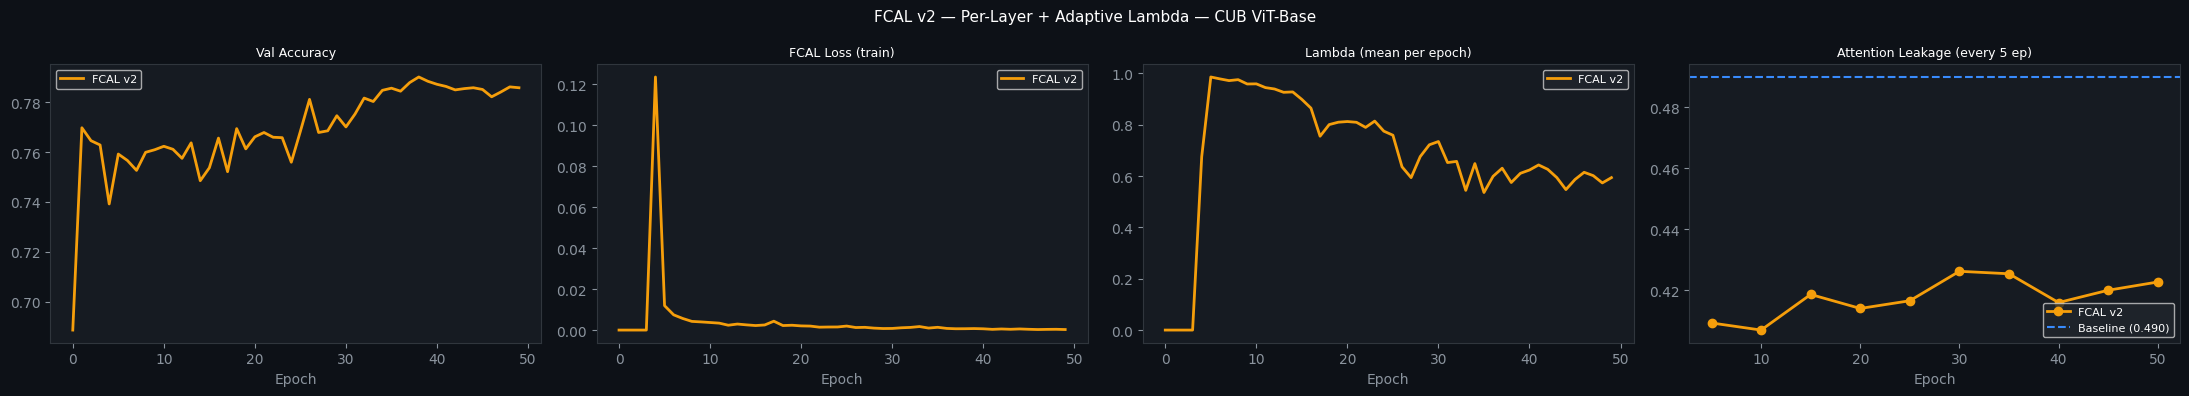

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
fig.patch.set_facecolor('#0D1117')

panels = [
    ('val_acc', 'Val Accuracy'),
    ('fcal',    'FCAL Loss (train)'),
    ('lambda',  'Lambda (mean per epoch)'),
    ('leak',    'Attention Leakage (every 5 ep)'),
]

colors = {'v2': '#F59E0B', 'baseline': '#388BFD'}

for ax, (key, title) in zip(axes, panels):
    ax.set_facecolor('#161B22')
    ax.spines[:].set_color('#30363D')
    ax.tick_params(colors='#8B949E')
    ax.set_title(title, color='white', fontsize=9)
    ax.set_xlabel('Epoch', color='#8B949E')

    vals_v2 = hist_v2[key]
    if key == 'leak':
        # Only plot non-nan leakage values
        xs = [i+1 for i, v in enumerate(vals_v2) if not math.isnan(v)]
        ys = [v   for v in vals_v2 if not math.isnan(v)]
        ax.plot(xs, ys, 'o-', color=colors['v2'], lw=2, markersize=6, label='FCAL v2')
        ax.axhline(baseline_leak, color=colors['baseline'], lw=1.5, ls='--', label=f'Baseline ({baseline_leak:.3f})')
    else:
        ax.plot(vals_v2, color=colors['v2'], lw=2, label='FCAL v2')

    ax.legend(facecolor='#21262D', labelcolor='white', fontsize=8)

plt.suptitle('FCAL v2 — Per-Layer + Adaptive Lambda — CUB ViT-Base', color='white', fontsize=11)
plt.tight_layout()
plt.savefig('fcal_v2_curves.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.show()

## 10 — Adaptive Lambda Behaviour Visualisation

This shows how lambda actually evolved during training —
the key thing to verify is that it started small and grew as CE decreased.

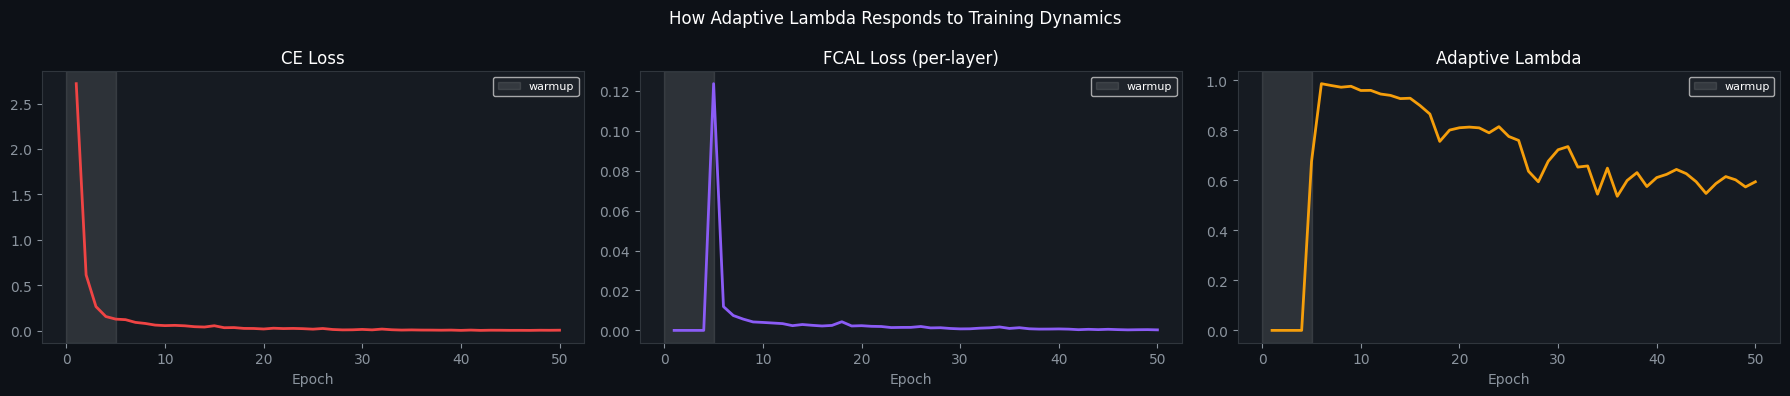

If working correctly you should see:
  Lambda starts small (CE is large, ratio ce/fcal is small)
  Lambda grows as CE drops (ratio grows)
  Lambda stabilizes when CE stops decreasing


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.patch.set_facecolor('#0D1117')

epochs_range = list(range(1, len(hist_v2['lambda']) + 1))

for ax, (key, color, title) in zip(axes, [
    ('ce',     '#EF4444', 'CE Loss'),
    ('fcal',   '#8B5CF6', 'FCAL Loss (per-layer)'),
    ('lambda', '#F59E0B', 'Adaptive Lambda'),
]):
    ax.set_facecolor('#161B22')
    ax.spines[:].set_color('#30363D')
    ax.tick_params(colors='#8B949E')
    ax.set_title(title, color='white')
    ax.set_xlabel('Epoch', color='#8B949E')
    ax.axvspan(0, CFG['warmup_epochs'], alpha=0.1, color='white', label='warmup')
    ax.plot(epochs_range, hist_v2[key], color=color, lw=2)
    ax.legend(facecolor='#21262D', labelcolor='white', fontsize=8)

plt.suptitle('How Adaptive Lambda Responds to Training Dynamics', color='white')
plt.tight_layout()
plt.savefig('adaptive_lambda_behaviour.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.show()

print('If working correctly you should see:')
print('  Lambda starts small (CE is large, ratio ce/fcal is small)')
print('  Lambda grows as CE drops (ratio grows)')
print('  Lambda stabilizes when CE stops decreasing')

## 11 — Attention Map Comparison: Baseline vs v1 vs v2

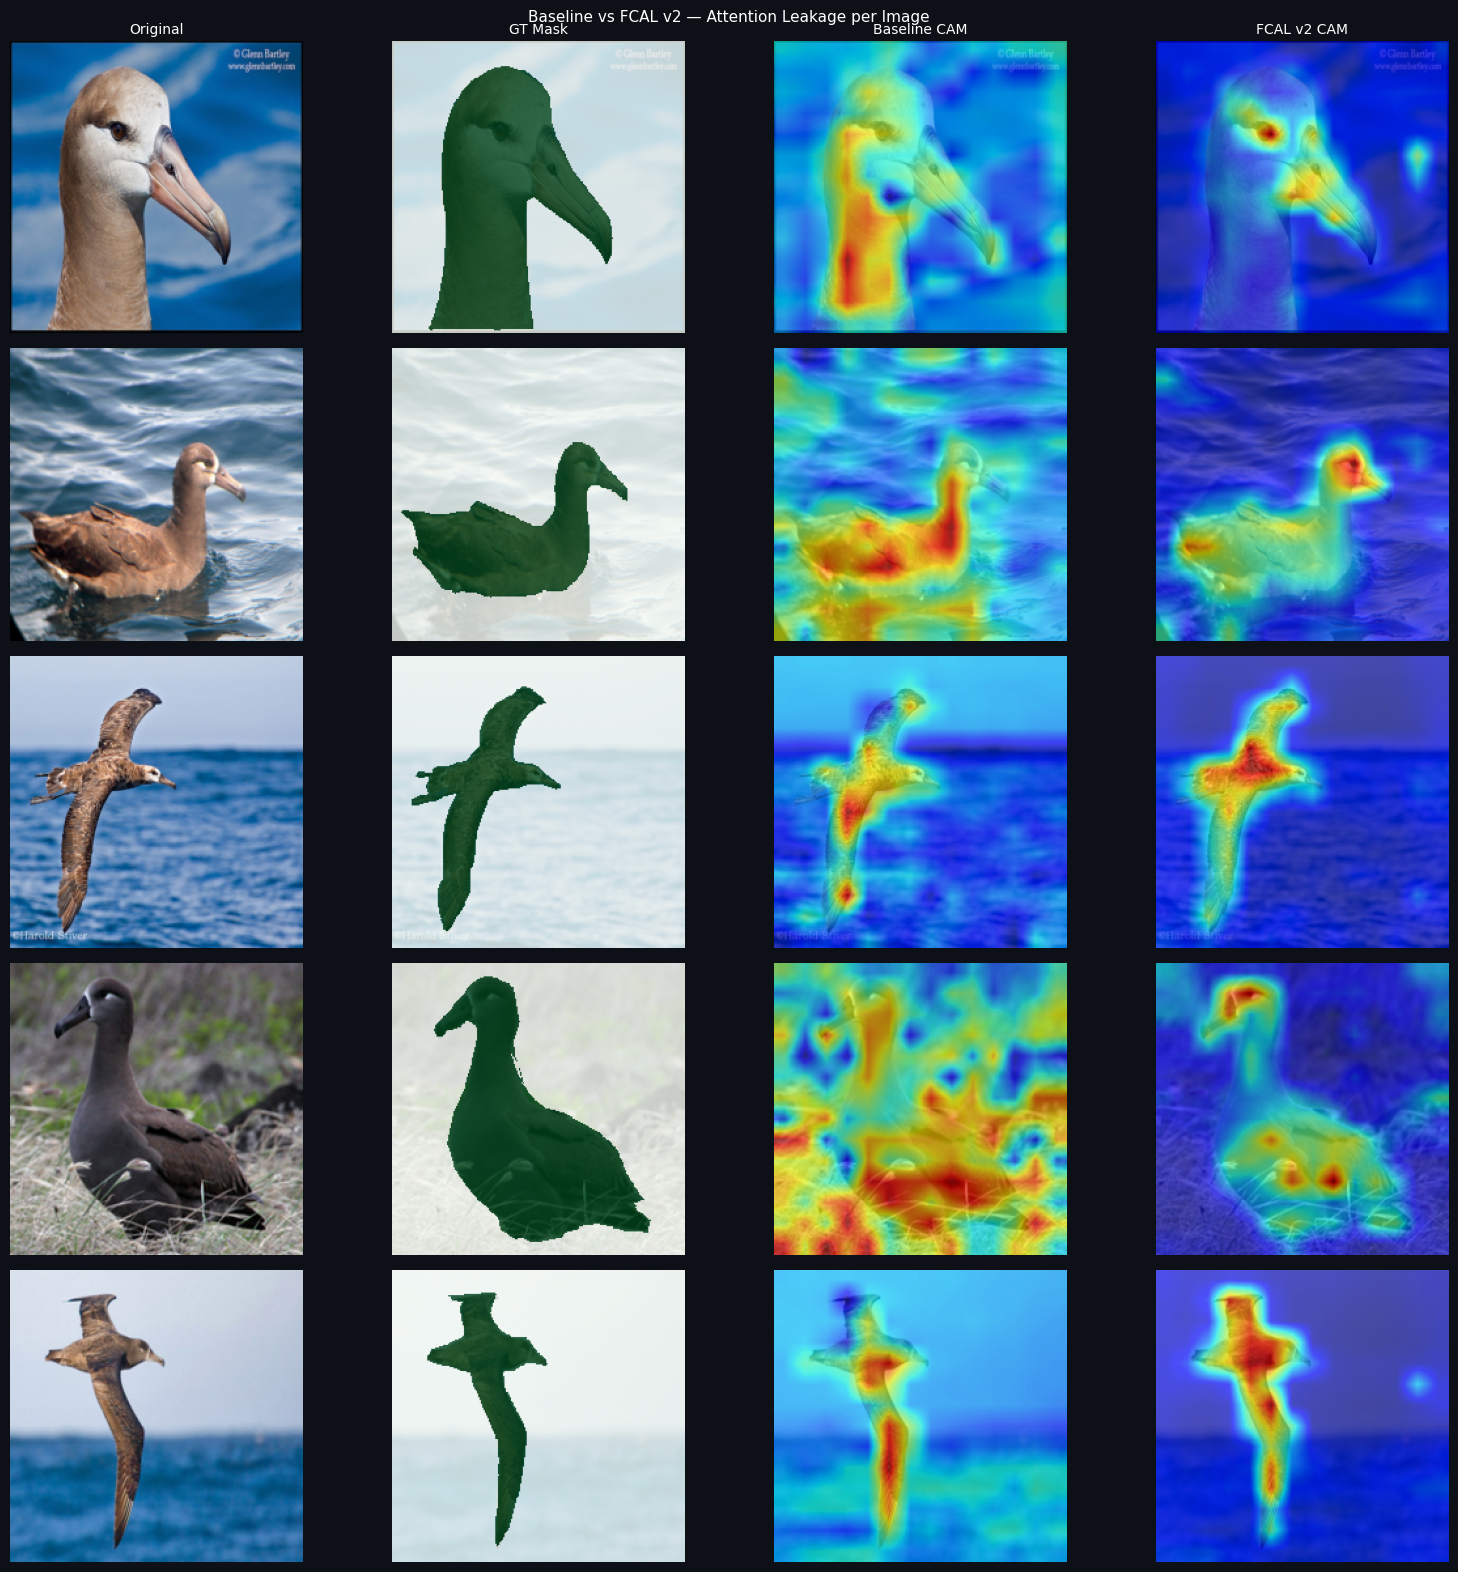

In [ ]:
@torch.no_grad()
def get_upsampled_rollout(model, imgs, device, size=224):
    model.eval()
    _ = model(imgs.to(device))
    cam = model.get_rollout_cam()
    return F.interpolate(
        cam.unsqueeze(1), size=(size, size),
        mode='bilinear', align_corners=False
    ).squeeze(1).cpu()


def per_image_leak(cam, mask):
    B = cam.shape[0]
    mask_r = F.interpolate(
        mask.unsqueeze(1) if mask.dim() == 3 else mask,
        size=cam.shape[-2:], mode='bilinear', align_corners=False
    ).squeeze(1)
    bg   = 1 - mask_r.clamp(0, 1)
    fl   = F.relu(cam).view(B, -1)
    prob = fl / (fl.sum(1, keepdim=True) + 1e-8)
    prob = prob.view(B, *cam.shape[-2:])
    return (prob * bg).sum(dim=(1, 2)).tolist()


imgs_v, labs_v, masks_v = next(iter(cub_test_loader))
N = 5
imgs_v, labs_v, masks_v = imgs_v[:N], labs_v[:N], masks_v[:N]

cam_base = get_upsampled_rollout(vit_baseline, imgs_v, DEVICE)
cam_v2   = get_upsampled_rollout(vit_v2,       imgs_v, DEVICE)

leaks_base = per_image_leak(cam_base, masks_v)
leaks_v2   = per_image_leak(cam_v2,   masks_v)

fig, axes = plt.subplots(N, 4, figsize=(16, N * 3.2))
fig.patch.set_facecolor('#0D1117')
col_titles = ['Original', 'GT Mask', 'Baseline CAM', 'FCAL v2 CAM']
for c, t in enumerate(col_titles):
    axes[0, c].set_title(t, color='white', fontsize=10, pad=6)

for i in range(N):
    img_np  = denorm(imgs_v[i]).permute(1, 2, 0).numpy()
    mask_np = masks_v[i, 0].numpy()
    cb_np   = cam_base[i].numpy()
    cv2_np  = cam_v2[i].numpy()

    for j, (d, cmap, alpha, ov) in enumerate([
        (img_np,  None,    1.0, False),
        (mask_np, 'Greens', 0.8, True),
        (cb_np,   'jet',   0.65, True),
        (cv2_np,  'jet',   0.65, True),
    ]):
        ax = axes[i, j]
        ax.axis('off')
        ax.set_facecolor('#0D1117')
        if ov:
            ax.imshow(img_np)
            ax.imshow(d, cmap=cmap, alpha=alpha, vmin=0, vmax=1)
        else:
            ax.imshow(d, cmap=cmap)
        if j == 2:
            ax.set_xlabel(f'leak={leaks_base[i]:.3f}', color='#388BFD', fontsize=8)
        if j == 3:
            ax.set_xlabel(f'leak={leaks_v2[i]:.3f}', color='#F59E0B', fontsize=8)

plt.suptitle('Baseline vs FCAL v2 — Attention Leakage per Image', color='white', fontsize=11)
plt.tight_layout()
plt.savefig('attention_v2_comparison.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.show()

## 12 — Summary for Paper Table

In [ ]:
rows = [
    ('CUB-200-2011', 'ViT-Base', 'Baseline (CE only)',               'N/A',  f'{baseline_leak:.4f}'),
    ('CUB-200-2011', 'ViT-Base', 'FCAL v1 (rollout, fixed λ=0.3)',   f'{v1_acc:.4f}', f'{v1_leak:.4f}'),
    ('CUB-200-2011', 'ViT-Base', 'FCAL v2 (per-layer, adaptive λ)',  f'{v2_acc:.4f}', f'{v2_leak:.4f}'),
]

summary = pd.DataFrame(rows, columns=['Dataset','Backbone','Method','Top-1 Acc','Leakage (lower=better)'])
print('\n' + '='*75)
print('PAPER TABLE — CUB ViT Results')
print('='*75)
print(summary.to_string(index=False))
summary.to_csv('fcal_v2_results.csv', index=False)
print('\nSaved to fcal_v2_results.csv')

# Leakage improvement over baseline
print(f'\nLeakage reduction v1 vs baseline: {(baseline_leak - v1_leak)*100:.1f}%')
print(f'Leakage reduction v2 vs baseline: {(baseline_leak - v2_leak)*100:.1f}%')
print(f'Leakage reduction v2 vs v1:       {(v1_leak - v2_leak)*100:.1f}%')


PAPER TABLE — CUB ViT Results
     Dataset Backbone                          Method Top-1 Acc Leakage (lower=better)
CUB-200-2011 ViT-Base              Baseline (CE only)       N/A                 0.4900
CUB-200-2011 ViT-Base  FCAL v1 (rollout, fixed λ=0.3)    0.8114                 0.4925
CUB-200-2011 ViT-Base FCAL v2 (per-layer, adaptive λ)    0.7901                 0.4102

Saved to fcal_v2_results.csv

Leakage reduction v1 vs baseline: -0.3%
Leakage reduction v2 vs baseline: 8.0%
Leakage reduction v2 vs v1:       8.2%


## 13 — ResNet-50 v2, then compare all six models

Train ResNet-50 with adaptive lambda FCAL v2, then evaluate and visualise:

- ResNet-50 baseline
- ResNet-50 FCAL v1
- ResNet-50 FCAL v2
- ViT-Base baseline
- ViT-Base FCAL v1
- ViT-Base FCAL v2

In [12]:
class ResNet50CAM(nn.Module):
    def __init__(self, num_classes=200, pretrained=False):
        super().__init__()
        bb = models.resnet50(weights='IMAGENET1K_V1' if pretrained else None)
        self.features = nn.Sequential(*list(bb.children())[:-2])
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(2048, num_classes)
        self._feat = None

    def forward(self, x):
        f = self.features(x)
        self._feat = f
        return self.classifier(self.gap(f).flatten(1))

    def get_cam_raw(self, class_idx):
        """Raw ReLU(CAM) with gradients intact — feed this to FCAL during training.
        No min-max stretching: that would destroy magnitude information and
        route gradients through per-image min/max statistics."""
        f = self._feat
        if f is None:
            raise RuntimeError('Call forward() before get_cam_raw().')
        w = self.classifier.weight[class_idx]
        return F.relu(torch.einsum('bc,bchw->bhw', w, f))

    def get_cam(self, class_idx):
        """Min-max normalized CAM in [0,1] — for VISUALIZATION and leakage metric only."""
        cam = self.get_cam_raw(class_idx)
        B = cam.shape[0]
        fl = cam.view(B, -1)
        mn = fl.min(1).values.view(B, 1, 1)
        mx = fl.max(1).values.view(B, 1, 1)
        return (cam - mn) / (mx - mn + 1e-8)


def load_checkpoint_into(model, ckpt_path, tag):
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(f'{tag} checkpoint not found: {ckpt_path}')
    state = torch.load(ckpt_path, map_location='cpu')
    if isinstance(state, dict) and 'state_dict' in state:
        state = state['state_dict']
    if any(k.startswith('module.') for k in state.keys()):
        state = {k.replace('module.', '', 1): v for k, v in state.items()}
    missing, unexpected = model.load_state_dict(state, strict=False)
    print(f'{tag}: loaded {ckpt_path} | missing={len(missing)} unexpected={len(unexpected)}')
    return model


def _resnet_v2_lambda(epoch, ce_value, fcal_value):
    """
    ResNet-v2 adaptive lambda — same GradNorm-style direction as the ViT branch:
    lambda = alpha * CE/FCAL, clipped to [lam_min, lam_max].

    The previous version used FCAL/CE, which saturated to lam_max almost
    immediately once CE dropped below ~0.5 and then stopped adapting.
    """
    warmup_epochs = CFG.get('warmup_epochs_resnet_v2', CFG.get('warmup_epochs', 5))
    adapt_alpha = CFG.get('adapt_alpha_resnet_v2', 0.15)
    lambda_max = CFG.get('lambda_max_resnet_v2', 0.30)
    lambda_min = CFG.get('lambda_min_resnet_v2', 0.02)

    if epoch < warmup_epochs:
        return 0.0
    if fcal_value < 1e-8:
        return lambda_min
    raw = adapt_alpha * (ce_value / (fcal_value + 1e-8))
    return float(np.clip(raw, lambda_min, lambda_max))


def train_epoch_resnet_v2(model, loader, optimizer, epoch, device):
    model.train()
    ce_fn = nn.CrossEntropyLoss()
    stats = dict(loss=0.0, ce=0.0, fcal=0.0, correct=0, total=0, lam_sum=0.0)

    for imgs, labels, masks in tqdm(loader, desc=f'  ep{epoch:02d}', leave=False):
        imgs, labels, masks = imgs.to(device), labels.to(device), masks.to(device)
        labels = labels.long()
        optimizer.zero_grad(set_to_none=True)

        logits = model(imgs)
        loss_ce = ce_fn(logits, labels)

        dilation_px = CFG.get('dilation_px', 3)
        warmup_epochs = CFG.get('warmup_epochs_resnet_v2', CFG.get('warmup_epochs', 5))

        if epoch < warmup_epochs:
            loss_fcal_v = 0.0
            lam = 0.0
            loss = loss_ce
        else:
            # v2.1: use RAW ReLU(CAM), not min-max stretched
            cam = model.get_cam_raw(class_idx=labels)
            if CFG.get('use_focal_containment', False):
                loss_fcal = fcal_loss_focal(cam, masks, dilation_px=dilation_px)
            else:
                loss_fcal = fcal_loss_v1(cam, masks, dilation_px=dilation_px)
            loss_fcal_v = float(loss_fcal.item())
            lam = _resnet_v2_lambda(epoch, loss_ce.item(), loss_fcal_v)
            loss = loss_ce + lam * loss_fcal

            # v2.1: optional intra-foreground entropy bonus
            ent_w = CFG.get('entropy_bonus_weight', 0.0)
            if ent_w > 0:
                cam_prob = normalize_cam(cam)
                ent = intra_fg_entropy(cam_prob, masks, dilation_px=dilation_px)
                loss = loss + lam * ent_w * ent

        if not torch.isfinite(loss):
            raise RuntimeError('Non-finite loss encountered during ResNet v2 training.')

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        stats['loss'] += loss.item()
        stats['ce'] += loss_ce.item()
        stats['fcal'] += loss_fcal_v
        stats['lam_sum'] += lam
        stats['correct'] += (logits.argmax(1) == labels).sum().item()
        stats['total'] += labels.size(0)

    n = len(loader)
    return {
        'acc': stats['correct'] / stats['total'],
        'loss': stats['loss'] / n,
        'ce': stats['ce'] / n,
        'fcal': stats['fcal'] / n,
        'lambda': stats['lam_sum'] / n,
    }


def run_resnet_v2(name='CUB ResNet50 FCAL v2', num_classes=200, epochs=None):
    epochs = epochs or CFG.get('num_epochs', 50)
    print(f'\n{"="*70}')
    print(f'  {name}  (adaptive lambda FCAL v2)  ep={epochs}')
    print(f'{"="*70}')

    resnet_lr = CFG.get('lr_resnet', CFG.get('lr', CFG.get('lr_vit', 2e-4)))
    weight_decay = CFG.get('weight_decay', 1e-4)

    model = ResNet50CAM(num_classes=num_classes, pretrained=True).to(DEVICE)  # v2.1: was False — that trained from scratch!
    optimizer = optim.AdamW(model.parameters(), lr=resnet_lr, weight_decay=weight_decay)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=resnet_lr * 0.01)

    hist = {k: [] for k in ['train_acc', 'val_acc', 'loss', 'ce', 'fcal', 'lambda', 'leak']}
    best_acc = 0.0
    best_path = 'ckpt_CUB_ResNet50_FCAL_v2.pth'

    for ep in range(1, epochs + 1):
        tr = train_epoch_resnet_v2(model, cub_train_loader, optimizer, ep, DEVICE)
        va = evaluate(model, cub_test_loader, DEVICE)
        scheduler.step()

        leak = compute_leakage(model, cub_test_loader, DEVICE, n_batches=50) if ep % 5 == 0 else float('nan')

        hist['train_acc'].append(tr['acc'])
        hist['val_acc'].append(va['acc'])
        hist['loss'].append(tr['loss'])
        hist['ce'].append(tr['ce'])
        hist['fcal'].append(tr['fcal'])
        hist['lambda'].append(tr['lambda'])
        hist['leak'].append(leak)

        if va['acc'] > best_acc:
            best_acc = va['acc']
            torch.save(model.state_dict(), best_path)

        leak_s = f'{leak:.4f}' if not math.isnan(leak) else '----'
        print(f'  ep{ep:02d}/{epochs}  tr={tr["acc"]:.4f}  va={va["acc"]:.4f}  '
              f'ce={tr["ce"]:.3f}  fcal={tr["fcal"]:.4f}  lam={tr["lambda"]:.3f}  '
              f'leak={leak_s}  best={best_acc:.4f}')

    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    return model, hist, best_acc


# Load ResNet baselines and train/load ResNet v2
CKPT_RESNET_BASE = '../ckpt_CUB_ResNet50_Baseline.pth'
CKPT_RESNET_V1   = '../ckpt_CUB_ResNet50_FCAL.pth'
CKPT_RESNET_V2   = 'ckpt_CUB_ResNet50_FCAL_v2.pth'

resnet_baseline = ResNet50CAM(num_classes=200, pretrained=True).to(DEVICE)
resnet_v1       = ResNet50CAM(num_classes=200, pretrained=True).to(DEVICE)

load_checkpoint_into(resnet_baseline, CKPT_RESNET_BASE, 'ResNet baseline')
load_checkpoint_into(resnet_v1,       CKPT_RESNET_V1,   'ResNet FCAL v1')

force_retrain = CFG.get('force_retrain_resnet_v2', False)
if force_retrain and os.path.exists(CKPT_RESNET_V2):
    os.remove(CKPT_RESNET_V2)
    print(f'Removed existing ResNet v2 checkpoint to retrain: {CKPT_RESNET_V2}')

if os.path.exists(CKPT_RESNET_V2):
    resnet_v2 = ResNet50CAM(num_classes=200, pretrained=False).to(DEVICE)
    load_checkpoint_into(resnet_v2, CKPT_RESNET_V2, 'ResNet FCAL v2')
    hist_resnet_v2 = {'train_acc': [], 'val_acc': [], 'loss': [], 'ce': [], 'fcal': [], 'lambda': [], 'leak': []}
    acc_resnet_v2 = evaluate(resnet_v2, cub_test_loader, DEVICE)['acc']
    print(f'ResNet FCAL v2 already exists: acc={acc_resnet_v2:.4f}')
else:
    resnet_v2, hist_resnet_v2, acc_resnet_v2 = run_resnet_v2(
        name='CUB ResNet50 FCAL v2',
        num_classes=200,
        epochs=CFG.get('num_epochs', 50),
    )
    print(f'Saved new ResNet FCAL v2 checkpoint: {CKPT_RESNET_V2}')

ResNet baseline: loaded ../ckpt_CUB_ResNet50_Baseline.pth | missing=0 unexpected=0
ResNet FCAL v1: loaded ../ckpt_CUB_ResNet50_FCAL.pth | missing=0 unexpected=0

  CUB ResNet50 FCAL v2  (adaptive lambda FCAL v2)  ep=50


  ep01:   0%|          | 0/187 [00:00<?, ?it/s]

  eval:   0%|          | 0/182 [00:00<?, ?it/s]

  ep01/50  tr=0.1957  va=0.3930  ce=3.768  fcal=0.0000  lam=0.000  leak=----  best=0.3930


  ep02:   0%|          | 0/187 [00:00<?, ?it/s]

...

  eval:   0%|          | 0/182 [00:00<?, ?it/s]

  ep49/50  tr=0.9992  va=0.7335  ce=0.003  fcal=0.0210  lam=0.035  leak=----  best=0.7354


  ep50:   0%|          | 0/187 [00:00<?, ?it/s]

  eval:   0%|          | 0/182 [00:00<?, ?it/s]

  ep50/50  tr=0.9993  va=0.7349  ce=0.004  fcal=0.0204  lam=0.033  leak=0.0443  best=0.7354
Saved new ResNet FCAL v2 checkpoint: ckpt_CUB_ResNet50_FCAL_v2.pth


In [ ]:
# Load ViT baseline/v1/v2 into a unified dict for six-model comparison
from pathlib import Path

def resolve_ckpt(*candidates):
    for candidate in candidates:
        if Path(candidate).exists():
            return str(Path(candidate))
    raise FileNotFoundError(f'Checkpoint not found. Tried: {candidates}')

CKPT_VIT_BASE = resolve_ckpt(CFG.get('ckpt_vit_base', 'ckpt_CUB_ViT_Baseline.pth'), '../ckpt_CUB_ViT_Baseline.pth')
CKPT_VIT_V1   = resolve_ckpt(CFG.get('ckpt_vit_v1', 'ckpt_CUB_ViT_FCAL.pth'), '../ckpt_CUB_ViT_FCAL.pth')
CKPT_VIT_V2   = resolve_ckpt(CFG.get('ckpt_vit_v2', 'ckpt_CUB_ViT_FCAL_v2_v2.pth'), 'ckpt_CUB_ViT_FCAL_v2_v2.pth', '../ckpt_CUB_ViT_FCAL_v2_v2.pth')

vit_base_cmp = ViTBaseV2(num_classes=200, pretrained=False).to(DEVICE)
vit_v1_cmp   = ViTBaseV2(num_classes=200, pretrained=False).to(DEVICE)
vit_v2_cmp   = ViTBaseV2(num_classes=200, pretrained=False).to(DEVICE)

load_checkpoint_into(vit_base_cmp, CKPT_VIT_BASE, 'ViT baseline')
load_checkpoint_into(vit_v1_cmp,   CKPT_VIT_V1,   'ViT FCAL v1')
load_checkpoint_into(vit_v2_cmp,   CKPT_VIT_V2,   'ViT FCAL v2')

models_all = {
    'resnet_base': resnet_baseline,
    'resnet_v1':   resnet_v1,
    'resnet_v2':   resnet_v2,
    'vit_base':    vit_base_cmp,
    'vit_v1':      vit_v1_cmp,
    'vit_v2':      vit_v2_cmp,
}

rows_all = []
for name, model in models_all.items():
    acc = evaluate(model, cub_test_loader, DEVICE)['acc']
    leak = compute_leakage(model, cub_test_loader, DEVICE, n_batches=50)
    rows_all.append((name, acc, leak))
    print(f'{name:<12} acc={acc:.4f}  leak={leak:.4f}')

summary_all = pd.DataFrame(rows_all, columns=['model', 'top1_acc', 'attn_leakage'])
summary_all['family'] = summary_all['model'].apply(lambda s: 'resnet50' if s.startswith('resnet') else 'vit-base')
summary_all['variant'] = summary_all['model'].apply(lambda s: s.split('_', 1)[1])

print('\n' + '=' * 72)
print('ALL-MODEL COMPARISON — CUB')
print('=' * 72)
print(summary_all.sort_values(['family', 'variant']).to_string(index=False))

summary_all.to_csv('all_models_v1_v2_comparison.csv', index=False)
print('\nSaved: all_models_v1_v2_comparison.csv')

FileNotFoundError: ViT baseline checkpoint not found: ckpt_CUB_ViT_Baseline.pth

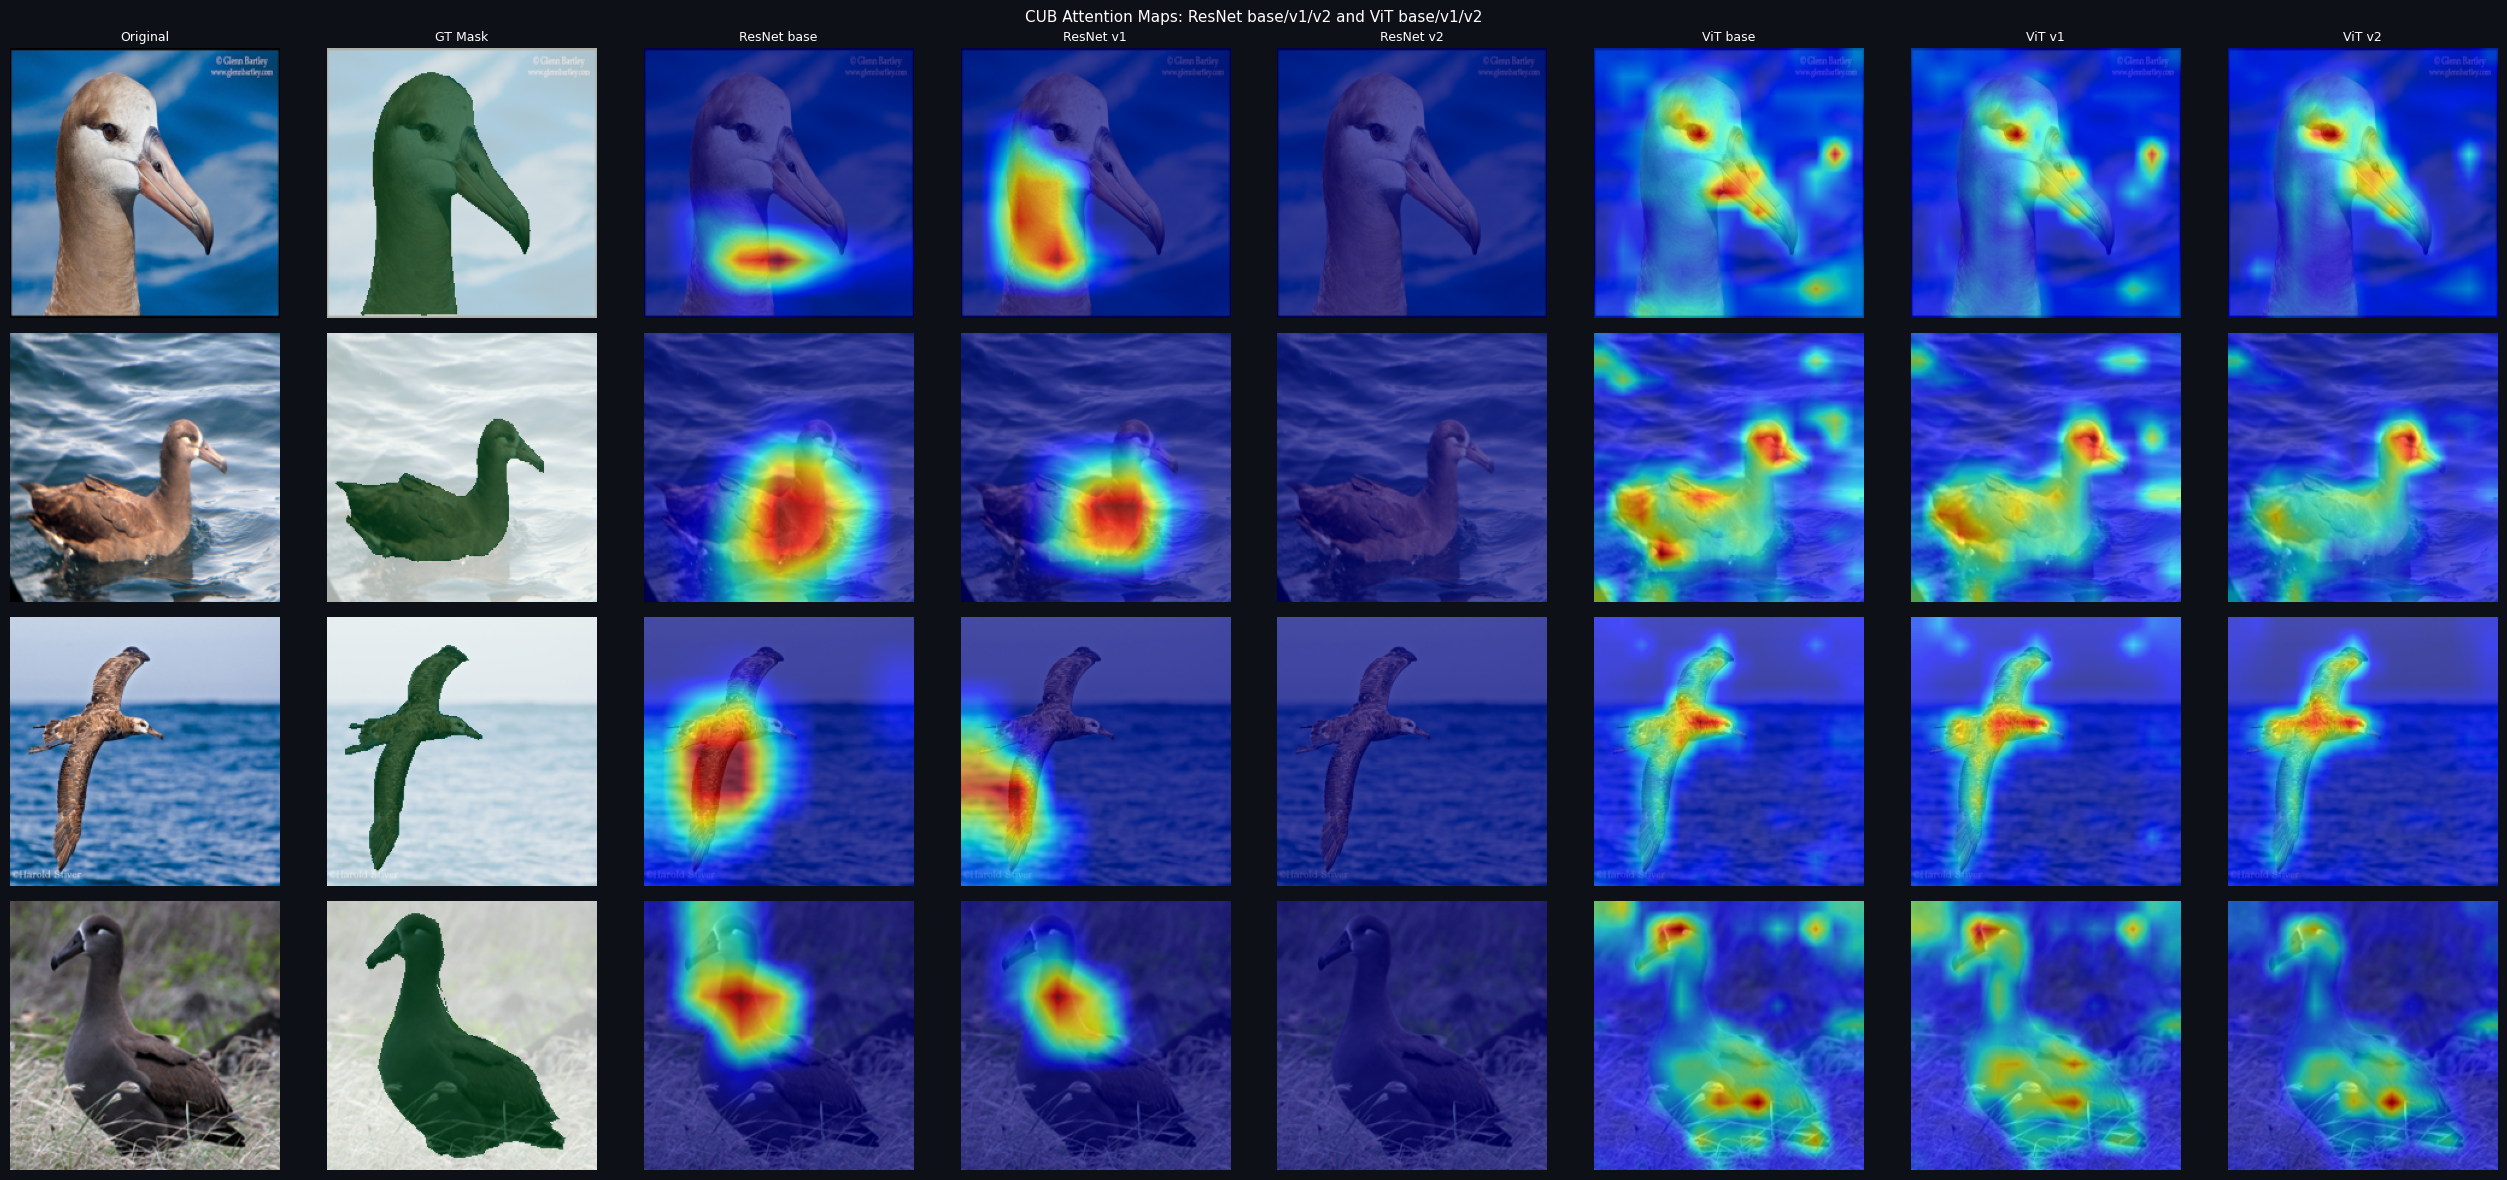

Saved: attention_all_6_models.png


In [ ]:
@torch.no_grad()
def get_upsampled_cam_any(model, imgs, labels, device, size=224):
    model.eval()
    _ = model(imgs.to(device))
    if hasattr(model, 'get_rollout_cam'):
        cam = model.get_rollout_cam()
    else:
        cam = model.get_cam(class_idx=labels.to(device))
    return F.interpolate(
        cam.unsqueeze(1),
        size=(size, size),
        mode='bilinear',
        align_corners=False,
    ).squeeze(1).cpu()


def per_image_leak(cam, mask):
    B = cam.shape[0]
    mask_r = F.interpolate(
        mask.unsqueeze(1) if mask.dim() == 3 else mask,
        size=cam.shape[-2:],
        mode='bilinear',
        align_corners=False,
    ).squeeze(1)
    bg = 1 - mask_r.clamp(0, 1)
    fl = F.relu(cam).view(B, -1)
    prob = fl / (fl.sum(1, keepdim=True) + 1e-8)
    prob = prob.view(B, *cam.shape[-2:])
    return (prob * bg).sum(dim=(1, 2)).tolist()


imgs_v, labs_v, masks_v = next(iter(cub_test_loader))
N = 4
imgs_v, labs_v, masks_v = imgs_v[:N], labs_v[:N], masks_v[:N]

cams_all = {
    'ResNet base': get_upsampled_cam_any(resnet_baseline, imgs_v, labs_v, DEVICE),
    'ResNet v1':   get_upsampled_cam_any(resnet_v1,       imgs_v, labs_v, DEVICE),
    'ResNet v2':   get_upsampled_cam_any(resnet_v2,       imgs_v, labs_v, DEVICE),
    'ViT base':    get_upsampled_cam_any(vit_base_cmp,    imgs_v, labs_v, DEVICE),
    'ViT v1':      get_upsampled_cam_any(vit_v1_cmp,      imgs_v, labs_v, DEVICE),
    'ViT v2':      get_upsampled_cam_any(vit_v2_cmp,      imgs_v, labs_v, DEVICE),
}

leaks_all = {k: per_image_leak(v, masks_v) for k, v in cams_all.items()}

col_titles = ['Original', 'GT Mask'] + list(cams_all.keys())
fig, axes = plt.subplots(N, len(col_titles), figsize=(3.2 * len(col_titles), 3.0 * N))
fig.patch.set_facecolor('#0D1117')
for c, t in enumerate(col_titles):
    axes[0, c].set_title(t, color='white', fontsize=9, pad=6)

for i in range(N):
    img_np = denorm(imgs_v[i]).permute(1, 2, 0).numpy()
    mask_np = masks_v[i, 0].numpy()

    ax = axes[i, 0]
    ax.imshow(img_np)
    ax.axis('off')
    ax.set_facecolor('#0D1117')

    ax = axes[i, 1]
    ax.imshow(img_np)
    ax.imshow(mask_np, cmap='Greens', alpha=0.7, vmin=0, vmax=1)
    ax.axis('off')
    ax.set_facecolor('#0D1117')

    for j, (name, cam_tensor) in enumerate(cams_all.items(), start=2):
        cam_np = cam_tensor[i].numpy()
        ax = axes[i, j]
        ax.imshow(img_np)
        ax.imshow(cam_np, cmap='jet', alpha=0.65, vmin=0, vmax=1)
        ax.axis('off')
        ax.set_facecolor('#0D1117')
        ax.set_xlabel(f"leak={leaks_all[name][i]:.3f}", color='white', fontsize=7)

plt.suptitle('CUB Attention Maps: ResNet base/v1/v2 and ViT base/v1/v2', color='white', fontsize=11)
plt.tight_layout()
plt.savefig('attention_all_6_models.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.show()

print('Saved: attention_all_6_models.png')